## Tephigram from BUFR data

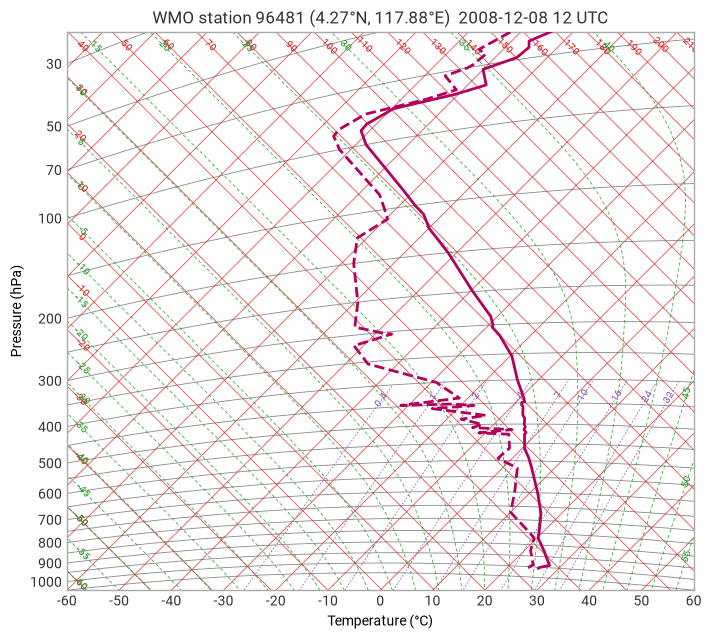

In [1]:
import earthkit.data as ekd
import earthkit.plots as ekp

# read BUFR data: the TEMP reports used by the Metview gallery
data = ekd.from_source(
    "url", "https://sites.ecmwf.int/repository/metview/test-data/gallery/temp.bufr"
)

# thermo_bufr(data=b, station=stations(search_key="ident", ident=96481))
# WMO station 96481 is block 96, station 481
df = data.to_pandas(
    columns=[
        "data_datetime", "latitude", "longitude",
        "pressure", "airTemperature", "dewpointTemperature",
    ],
    filters={"blockNumber": 96, "stationNumber": 481},
)

# thermoview(type="tephigram", minimum_temperature=-120, maximum_temperature=35,
#            top_pressure=100)
# earthkit-plots measures the temperature range along the bottom isobar, so the
# default range already contains the sounding; Metview's default bottom
# pressure is 1015 hPa
tephi = ekp.Tephigram()

# mthermo(thermo_temperature_line_colour="purplish_red",
#         thermo_temperature_line_thickness=6, ...)
# The profiles are read from the columns of the DataFrame. Levels that report
# only wind are dropped from each profile (Metview's
# thermo_*_missing_data_* settings), and the other columns are kept as
# metadata for the title.
purplish_red = "#b3005c"
tephi.temperature(
    df, column="airTemperature", p="pressure", units="K", p_units="Pa",
    color=purplish_red, linewidth=2,
)
tephi.dewpoint(
    df, column="dewpointTemperature", p="pressure", units="K", p_units="Pa",
    color=purplish_red, linewidth=2,
)

# The latitude, longitude and time of the station are constant columns of the
# DataFrame, so they are available to the title like xarray scalar coordinates
tephi.title("WMO station 96481 ({latitude:%Lt}, {longitude:%Ln})  {time:%Y-%m-%d %H} UTC")

# setoutput(pdf_output(output_name="tephigram_bufr"))
tephi.show()